In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Üst dizindeki artifacts klasöründen yalnızca eğitim verisini yükleme
artifact_dir = "../artifacts"
print("artifacts klasörü içeriği:", os.listdir(artifact_dir))

train_fe = pd.read_csv(os.path.join(artifact_dir, "train_fe.csv"))

with open(os.path.join(artifact_dir, "selected_features.json"), "r") as f:
    selected_features = json.load(f)

# 2. EDA grafiklerinin kullanacağı temel sensör değişkenlerini hazırlama
ignore_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}
base_feature_cols = [
    c for c in train_fe.columns
    if c not in ignore_cols and not any(suffix in c for suffix in ["_roll_", "_diff"])
]

train_clean = train_fe[["unit", "cycle"] + base_feature_cols + ["RUL_capped125"]].copy()

print("\nEğitim verisi başarıyla yüklendi!")
print(f"train_fe          : {train_fe.shape}")
print(f"Temel sensör sayısı: {len(base_feature_cols)}")

artifacts klasörü içeriği: ['selected_features.json', 'test_fe.csv', 'train_fe.csv', 'val_fe.csv']

Eğitim verisi başarıyla yüklendi!
train_fe          : (16561, 72)
Temel sensör sayısı: 17


## 3. Keşifçi Veri Analizi (EDA)

Bu bölümde temizlenmiş ve öznitelikleri türetilmiş veri setleri (`train_fe`, `test_fe`, `rul_df`) üzerinde dağılım, korelasyon, dengesizlik ve görselleştirme analizleri yapılmaktadır. Tüm istatistiksel çıkarımlar veri sızıntısını önlemek amacıyla yalnızca eğitim seti üzerinden gerçekleştirilmiştir.

### 3.1. Yaşam Süresi Analizi (Survival Analysis)

* **Amaç:** Eğitim setindeki motorların arızalanana kadar geçen toplam çalışma döngülerinin (`cycle`) dağılımını ve uç değerlerini belirlemek.

=== EĞİTİM SETİ MOTOR ÖMÜR İSTATİSTİKLERİ ===
Toplam Motor Sayısı : 80
Ortalama Ömür       : 207.01 döngü
Medyan Ömür         : 199.00 döngü
En Kısa Ömür        : 128 döngü (Unit 39)
En Uzun Ömür        : 362 döngü (Unit 69)


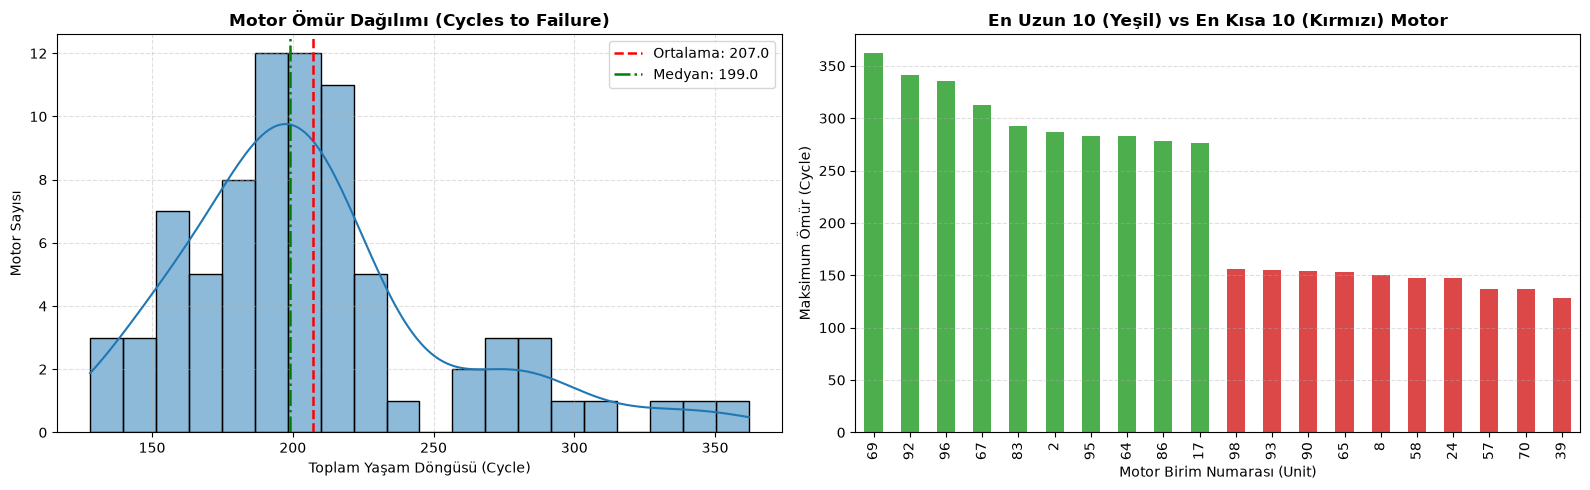

In [2]:
engine_lifespan = train_clean.groupby("unit")["cycle"].max()

print("=== EĞİTİM SETİ MOTOR ÖMÜR İSTATİSTİKLERİ ===")
print(f"Toplam Motor Sayısı : {len(engine_lifespan)}")
print(f"Ortalama Ömür       : {engine_lifespan.mean():.2f} döngü")
print(f"Medyan Ömür         : {engine_lifespan.median():.2f} döngü")
print(f"En Kısa Ömür        : {engine_lifespan.min()} döngü (Unit {engine_lifespan.idxmin()})")
print(f"En Uzun Ömür        : {engine_lifespan.max()} döngü (Unit {engine_lifespan.idxmax()})")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(engine_lifespan, kde=True, color="#1f77b4", bins=20, ax=axes[0])
axes[0].axvline(engine_lifespan.mean(), color="red", linestyle="--", linewidth=1.8, label=f"Ortalama: {engine_lifespan.mean():.1f}")
axes[0].axvline(engine_lifespan.median(), color="green", linestyle="-.", linewidth=1.8, label=f"Medyan: {engine_lifespan.median():.1f}")
axes[0].set_title("Motor Ömür Dağılımı (Cycles to Failure)", fontweight="bold")
axes[0].set_xlabel("Toplam Yaşam Döngüsü (Cycle)")
axes[0].set_ylabel("Motor Sayısı")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

sorted_lifespan = engine_lifespan.sort_values(ascending=False)
extremes = pd.concat([sorted_lifespan.head(10), sorted_lifespan.tail(10)])
colors = ["#2ca02c"] * 10 + ["#d62728"] * 10

extremes.plot(kind="bar", color=colors, alpha=0.85, ax=axes[1])
axes[1].set_title("En Uzun 10 (Yeşil) vs En Kısa 10 (Kırmızı) Motor", fontweight="bold")
axes[1].set_xlabel("Motor Birim Numarası (Unit)")
axes[1].set_ylabel("Maksimum Ömür (Cycle)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.2. Sensör Bozulma Eğilimleri

* **Amaç:** Motorlar arızaya yaklaştıkça (`RUL -> 0`) kritik sensör ölçümlerinin zamana bağlı değişim yönünü (`mean ± std`) incelemek.

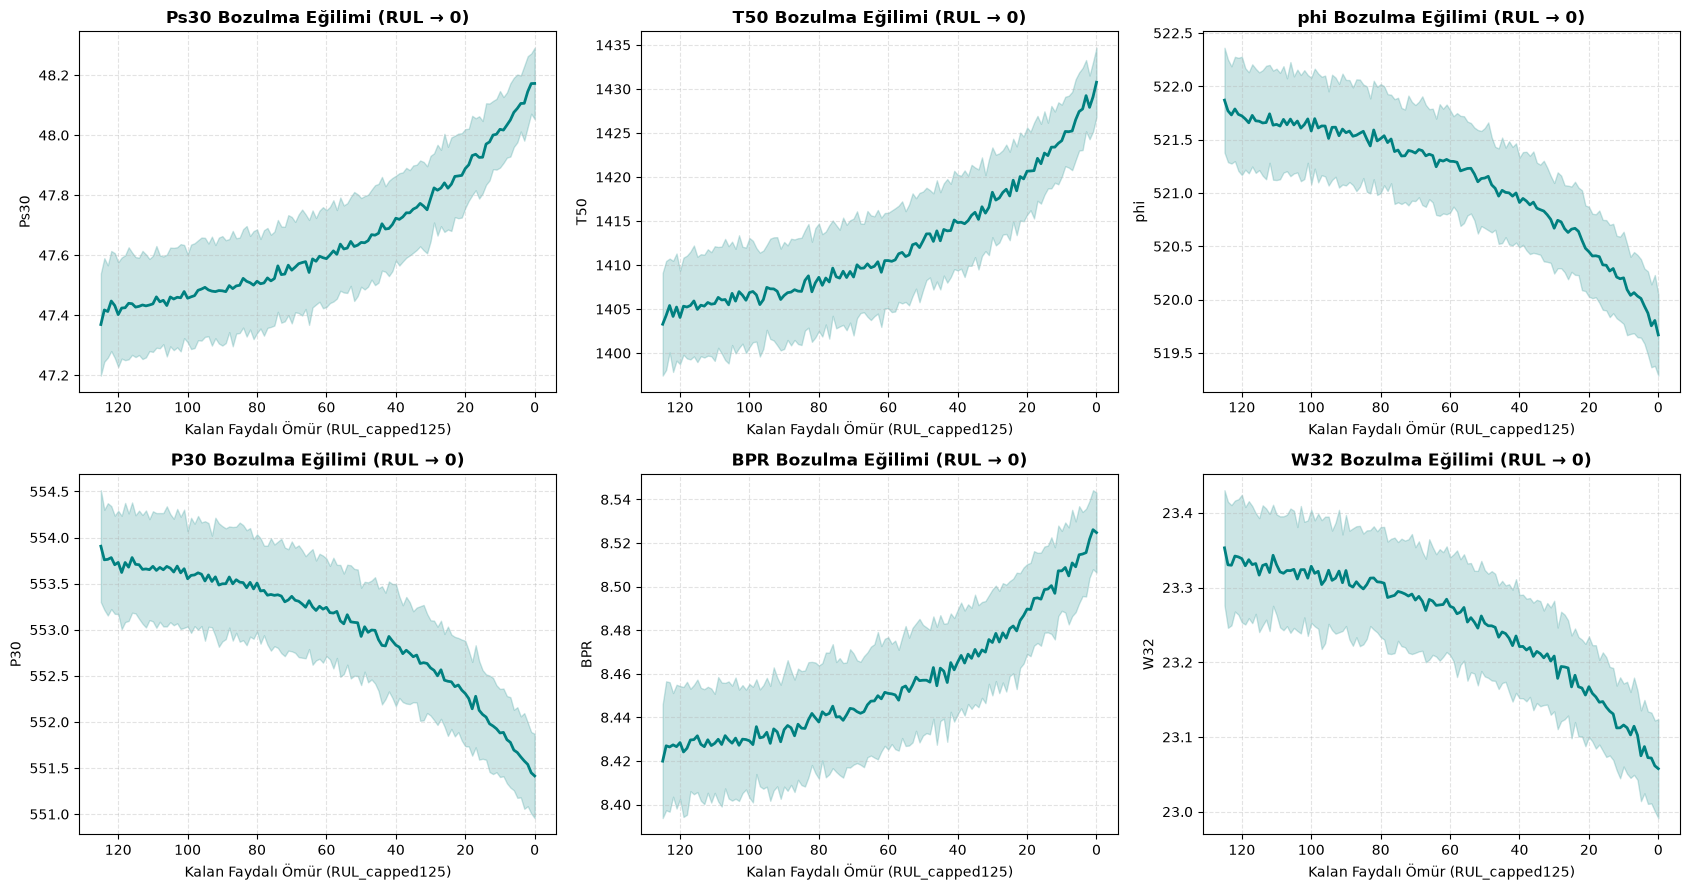

In [3]:
top_sensors = ["Ps30", "T50", "phi", "P30", "BPR", "W32"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for i, sensor in enumerate(top_sensors):
    sns.lineplot(
        data=train_clean,
        x="RUL_capped125",
        y=sensor,
        ax=axes[i],
        errorbar="sd",
        color="#008080",
        linewidth=2
    )
    axes[i].invert_xaxis()
    axes[i].set_title(f"{sensor} Bozulma Eğilimi (RUL → 0)", fontweight="bold")
    axes[i].set_xlabel("Kalan Faydalı Ömür (RUL_capped125)")
    axes[i].set_ylabel(sensor)
    axes[i].grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### 3.3. Korelasyon ve Öznitelik Katkı Analizi

* **Amaç:** Temel sensörler arasındaki korelasyonu (`heatmap`) incelemek ve türetilen yeni özelliklerin (`roll_mean_10`, `roll_std_10`, `diff`) `RUL_capped125` ile ilişkisini kıyaslamak.

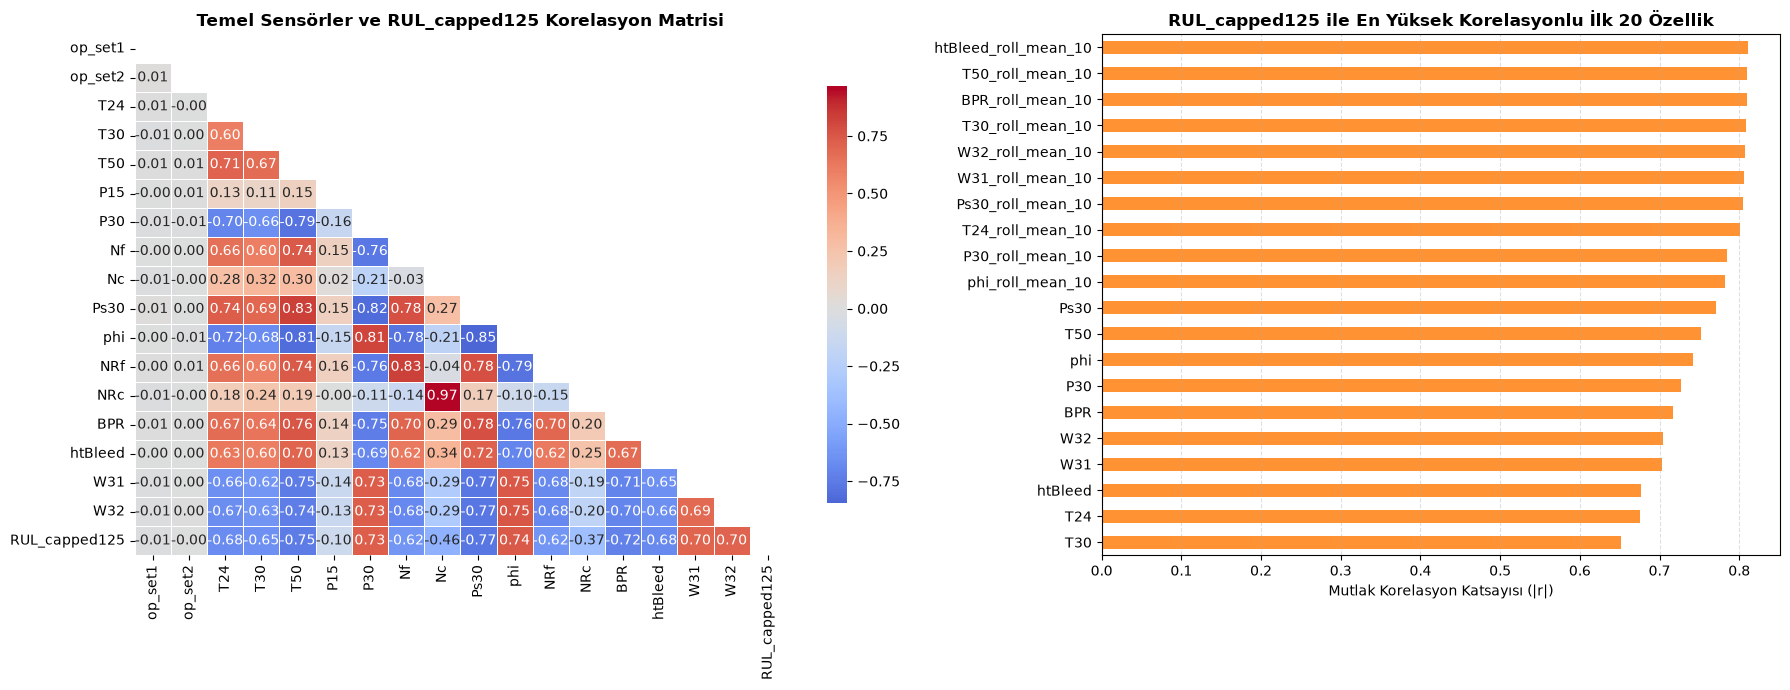

=== EN YÜKSEK KORELASYONLU İLK 15 ÖZELLİK ===
htBleed_roll_mean_10    0.8106
T50_roll_mean_10        0.8097
BPR_roll_mean_10        0.8092
T30_roll_mean_10        0.8081
W32_roll_mean_10        0.8072
W31_roll_mean_10        0.8064
Ps30_roll_mean_10       0.8047
T24_roll_mean_10        0.8012
P30_roll_mean_10        0.7849
phi_roll_mean_10        0.7815
Ps30                    0.7712
T50                     0.7523
phi                     0.7424
P30                     0.7275
BPR                     0.7167
dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.2, 1]})

corr_matrix = train_clean[base_feature_cols + ["RUL_capped125"]].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=axes[0]
)
axes[0].set_title("Temel Sensörler ve RUL_capped125 Korelasyon Matrisi", fontweight="bold")

fe_cols = [c for c in train_fe.columns if c not in {"unit", "cycle", "RUL_linear", "RUL_capped125"}]
correlations = train_fe[fe_cols].corrwith(train_fe["RUL_capped125"]).abs().sort_values(ascending=False)

correlations.head(20).sort_values().plot(kind="barh", color="#ff7f0e", alpha=0.85, ax=axes[1])
axes[1].set_title("RUL_capped125 ile En Yüksek Korelasyonlu İlk 20 Özellik", fontweight="bold")
axes[1].set_xlabel("Mutlak Korelasyon Katsayısı (|r|)")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print("=== EN YÜKSEK KORELASYONLU İLK 15 ÖZELLİK ===")
print(correlations.head(15).round(4))

### 3.4. Hedef Değişken (RUL) Dağılımı, Kırpma Etkisi ve Sensör Saçılım Analizi

* **Amaç:** Sürekli regresyon hedefi olan `RUL_linear` ile `RUL_capped125` dağılımlarını karşılaştırmak, kırpma işleminin sağa çarpıklığı (skewness) nasıl giderdiğini göstermek ve RUL bölgelerindeki örnek yoğunluğunun regresyon hata metriklerine etkisini incelemektir.

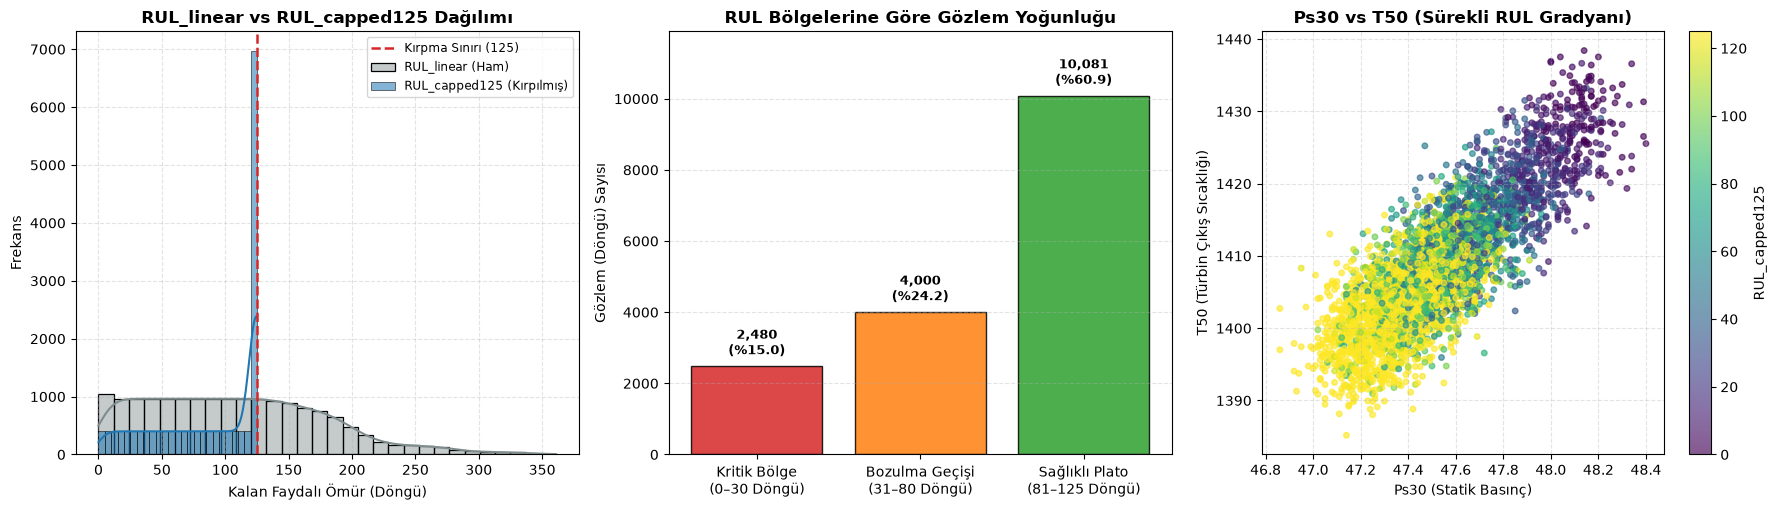

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# 1. Sol Grafik: RUL_linear vs RUL_capped125 Dağılım Karşılaştırması
sns.histplot(train_fe["RUL_linear"], bins=30, kde=True, color="#7f8c8d", alpha=0.45, label="RUL_linear (Ham)", ax=axes[0])
sns.histplot(train_fe["RUL_capped125"], bins=25, kde=True, color="#1f77b4", alpha=0.55, label="RUL_capped125 (Kırpılmış)", ax=axes[0])
axes[0].axvline(125, color="#d62728", linestyle="--", linewidth=1.8, label="Kırpma Sınırı (125)")
axes[0].set_title("RUL_linear vs RUL_capped125 Dağılımı", fontweight="bold")
axes[0].set_xlabel("Kalan Faydalı Ömür (Döngü)")
axes[0].set_ylabel("Frekans")
axes[0].legend(fontsize=8.5)
axes[0].grid(True, linestyle="--", alpha=0.35)

# 2. Orta Grafik: Sürekli RUL Bölgelerine Göre Eğitim Verisi Yoğunluğu
rul_zones = pd.cut(
    train_fe["RUL_capped125"],
    bins=[-1, 30, 80, 125],
    labels=["Kritik Bölge\n(0–30 Döngü)", "Bozulma Geçişi\n(31–80 Döngü)", "Sağlıklı Plato\n(81–125 Döngü)"]
)
zone_counts = rul_zones.value_counts().sort_index()
zone_pcts = (zone_counts / len(train_fe)) * 100

bars = axes[1].bar(zone_counts.index, zone_counts.values, color=["#d62728", "#ff7f0e", "#2ca02c"], edgecolor="black", alpha=0.85)
axes[1].set_title("RUL Bölgelerine Göre Gözlem Yoğunluğu", fontweight="bold")
axes[1].set_ylabel("Gözlem (Döngü) Sayısı")
axes[1].set_ylim(0, zone_counts.max() * 1.18)
axes[1].grid(axis="y", linestyle="--", alpha=0.35)

for bar, cnt, pct in zip(bars, zone_counts.values, zone_pcts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        cnt + 220,
        f"{cnt:,}\n(%{pct:.1f})",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# 3. Sağ Grafik: Ps30 vs T50 Sürekli RUL Gradyanı
sample_df = train_clean.sample(n=min(4000, len(train_clean)), random_state=42)
sc = axes[2].scatter(
    sample_df["Ps30"],
    sample_df["T50"],
    c=sample_df["RUL_capped125"],
    cmap="viridis",
    alpha=0.65,
    s=16
)
plt.colorbar(sc, ax=axes[2], label="RUL_capped125")
axes[2].set_title("Ps30 vs T50 (Sürekli RUL Gradyanı)", fontweight="bold")
axes[2].set_xlabel("Ps30 (Statik Basınç)")
axes[2].set_ylabel("T50 (Türbin Çıkış Sıcaklığı)")
axes[2].grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### 3.5. Sağlık Durumu Ayrışması (KDE) ve 2B PCA Bozulma Yörüngesi

* **Amaç:** Motorun ilk 20 döngüsü (sağlıklı) ile son 20 döngüsü (arızaya yakın) arasındaki sensör dağılım ayrışmasını (`KDE`) incelemek ve tüm öznitelik uzayını (`train_fe`) `PCA` ile 2 boyuta indirgeyerek bozulma yörüngesini görselleştirmek.

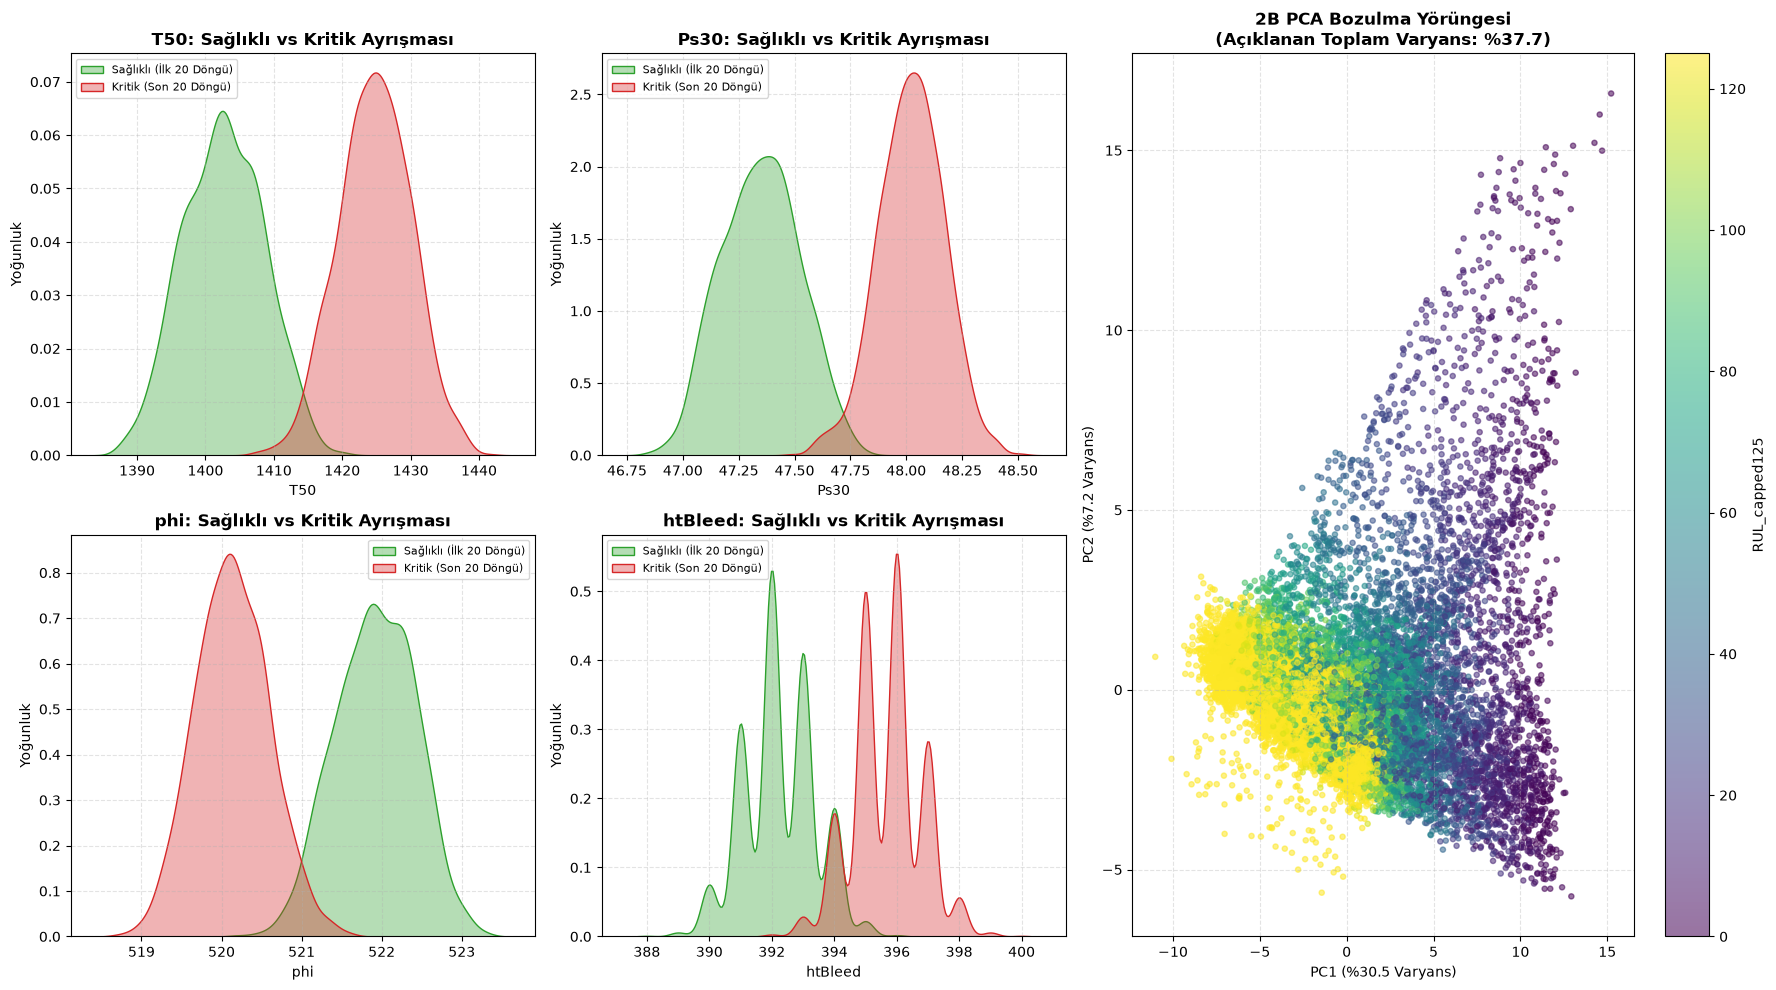

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.35])

# 1. Sol 4 Grafik: Sağlıklı (İlk 20 Döngü) vs Arızaya Yakın (Son 20 Döngü) KDE Ayrışması
early_life = train_clean[train_clean["cycle"] <= 20]
late_life  = train_clean[train_clean["RUL_capped125"] <= 20]

sensors_to_compare = ["T50", "Ps30", "phi", "htBleed"]
kde_positions = [(0, 0), (0, 1), (1, 0), (1, 1)]

for idx, sensor in enumerate(sensors_to_compare):
    ax = fig.add_subplot(gs[kde_positions[idx]])
    sns.kdeplot(early_life[sensor], fill=True, color="#2ca02c", label="Sağlıklı (İlk 20 Döngü)", ax=ax, alpha=0.35)
    sns.kdeplot(late_life[sensor], fill=True, color="#d62728", label="Kritik (Son 20 Döngü)", ax=ax, alpha=0.35)
    ax.set_title(f"{sensor}: Sağlıklı vs Kritik Ayrışması", fontweight="bold")
    ax.set_xlabel(sensor)
    ax.set_ylabel("Yoğunluk")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(fontsize=8)

# 2. Sağ Büyük Grafik: Tüm Özniteliklerin 2B PCA Bozulma Yörüngesi
ax_pca = fig.add_subplot(gs[:, 2])

X_scaled = StandardScaler().fit_transform(train_fe[fe_cols])
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)

sc = ax_pca.scatter(
    pca_components[:, 0],
    pca_components[:, 1],
    c=train_fe["RUL_capped125"],
    cmap="viridis",
    alpha=0.55,
    s=14
)
plt.colorbar(sc, ax=ax_pca, label="RUL_capped125")
ax_pca.set_title(
    f"2B PCA Bozulma Yörüngesi\n(Açıklanan Toplam Varyans: %{pca.explained_variance_ratio_.sum()*100:.1f})",
    fontweight="bold"
)
ax_pca.set_xlabel(f"PC1 (%{pca.explained_variance_ratio_[0]*100:.1f} Varyans)")
ax_pca.set_ylabel(f"PC2 (%{pca.explained_variance_ratio_[1]*100:.1f} Varyans)")
ax_pca.grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### 3.6. EDA Özeti ve Modelleme Çıkarımları

* **Yaşam Süresi ve Hedef Yapısı:** Eğitim setindeki motorların arızaya kadar geçen ömürleri 128 ile 362 döngü arasında değişmekte olup ortalama ~206 döngü (medyan ~199 döngü) seviyesindedir. `RUL_linear` hedefindeki sağa çarpık uzun kuyruk `RUL_capped125` ile sınırlandırılarak fiziksel sensör kırılma noktalarıyla uyumlu hale getirilmiştir.
* **Sensör Bozulma Eğilimleri ve Öznitelik Katkısı:** Arıza yaklaştıkça (`RUL -> 0`) `Ps30`, `T50`, `BPR` ve `htBleed` sensörlerinde belirgin artış; `phi`, `P30` ve `W32` sensörlerinde ise düşüş gözlemlenmiştir. Özellik mühendisliği kapsamında türetilen 10 döngülük hareketli ortalamalar (`_roll_mean_10`), anlık sensör gürültüsünü bastırarak `RUL_capped125` ile mutlak korelasyonu 0.80–0.81 bandına taşımış ve ilk 10 sıranın tamamını oluşturmuştur.
* **Hedef Yoğunluğu ve Regresyon Metrik Stratejisi:** Gözlemlerin ~%60.8'i sağlıklı platoda (`81–125` döngü), ~%15.0'i ise kritik arıza bölgesinde (`0–30` döngü) yer almaktadır. Regresyon modellerinin çoğunluk bölgesine yanlı davranmasını engellemek amacıyla model değerlendirmesinde genel `RMSE` ve `MAE` metriklerinin yanında **kritik bölge (`RUL <= 30`) RMSE** ve **asimetrik PHM08 skor fonksiyonu** kullanılacaktır.
* **Sağlık Ayrışması ve 2B PCA Yörüngesi:** KDE dağılımları ilk 20 döngü ile son 20 döngü arasında keskin bir ayrışma olduğunu, 2B PCA projeksiyonu ise tüm öznitelik uzayının sağlıklı bölgeden arıza eşiğine doğru tek yönlü bir bozulma yörüngesi izlediğini doğrulamıştır.